# Renewable Solar/Wind Energy Output Forecast

**Goal:** forecast hourly power output (MW) of a 50 MWp solar plant and a 60 MW wind farm from weather conditions, time-of-day/season signals and recent output history, and compare four machine learning regressors against a persistence baseline.

**Data:** `renewable_energy_data.csv` - 17,544 hourly rows (2023-01-01 to 2024-12-31). The dataset is **synthetic** (physics-based simulation with noise and random outages), so results demonstrate the method, not the performance on a real site.

**Pipeline:** load -> EDA -> feature engineering -> chronological train/test split -> 4 models + baseline -> evaluation (MAE, RMSE, R2, nRMSE) -> time-series cross-validation -> feature importance.

In [1]:
import warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.model_selection import TimeSeriesSplit
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

sns.set_theme(style="whitegrid", context="notebook")
RANDOM_STATE = 42
SOLAR_CAP, WIND_CAP = 50.0, 60.0   # plant capacities in MW

## 1. Load data

In [2]:
df = pd.read_csv("renewable_energy_data.csv", parse_dates=["timestamp"])
df = df.set_index("timestamp").sort_index()

print("Shape:", df.shape)
print("Period:", df.index.min(), "->", df.index.max())
print("Missing values:", int(df.isna().sum().sum()))
print("Regular hourly index:", (df.index.to_series().diff().dropna() == pd.Timedelta("1h")).all())
print()
print(df.head().to_string())
print()
print(df.describe().T.round(2).to_string())

Shape: (17544, 10)
Period: 2023-01-01 00:00:00 -> 2024-12-31 23:00:00
Missing values: 0
Regular hourly index: True

                     temperature_c  humidity_pct  pressure_hpa  cloud_cover_pct  ghi_wm2  wind_speed_ms  wind_direction_deg  solar_output_mw  wind_output_mw  total_output_mw
timestamp                                                                                                                                                                    
2023-01-01 00:00:00          17.42          92.8        1004.2             20.1      0.0           4.93                50.0              0.0           3.126            3.126
2023-01-01 01:00:00          16.83          91.5        1005.3             16.3      0.0           4.84                68.0              0.0           2.923            2.923
2023-01-01 02:00:00          15.84          93.4        1006.0             25.9      0.0           4.67                49.0              0.0           2.670            2.670
2023-01-01 03:

## 2. Exploratory data analysis

### 2.1 A sample week in the monsoon and in winter

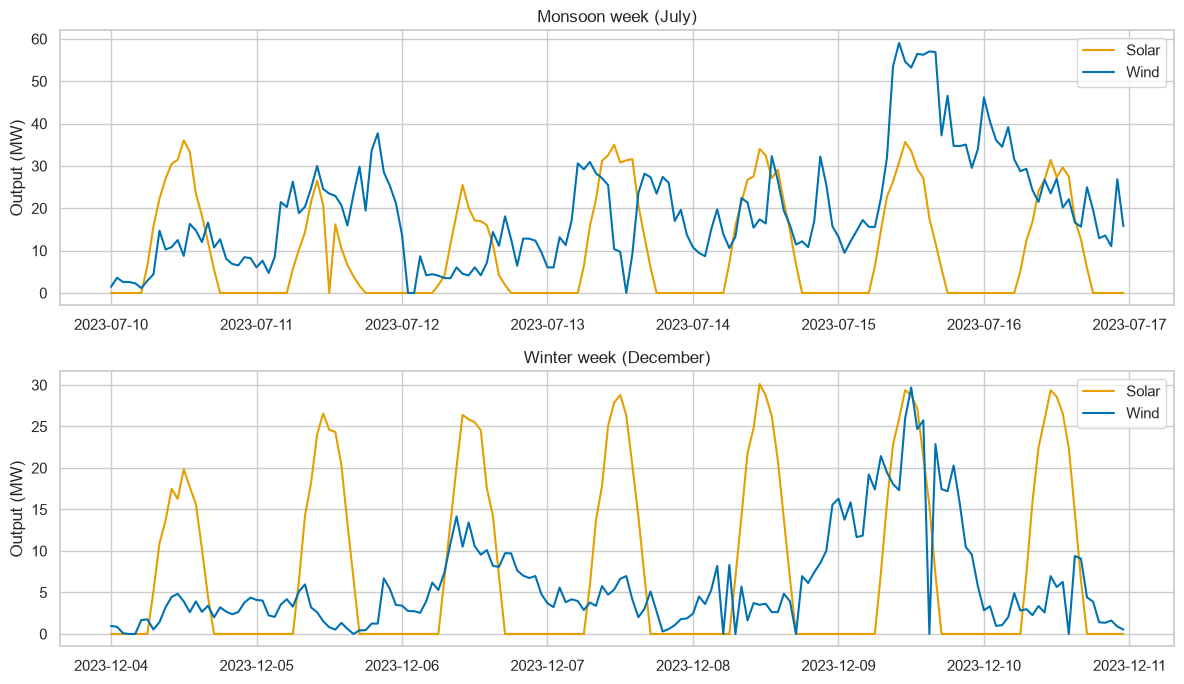

In [3]:
fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharey=False)
for ax, (start, label) in zip(axes, [("2023-07-10", "Monsoon week (July)"), ("2023-12-04", "Winter week (December)")]):
    wk = df.loc[start:pd.Timestamp(start) + pd.Timedelta("6D 23h")]
    ax.plot(wk.index, wk.solar_output_mw, label="Solar", color="#e69f00")
    ax.plot(wk.index, wk.wind_output_mw, label="Wind", color="#0072b2")
    ax.set_title(label); ax.set_ylabel("Output (MW)"); ax.legend(loc="upper right")
plt.tight_layout(); plt.show()

### 2.2 Seasonal and daily patterns

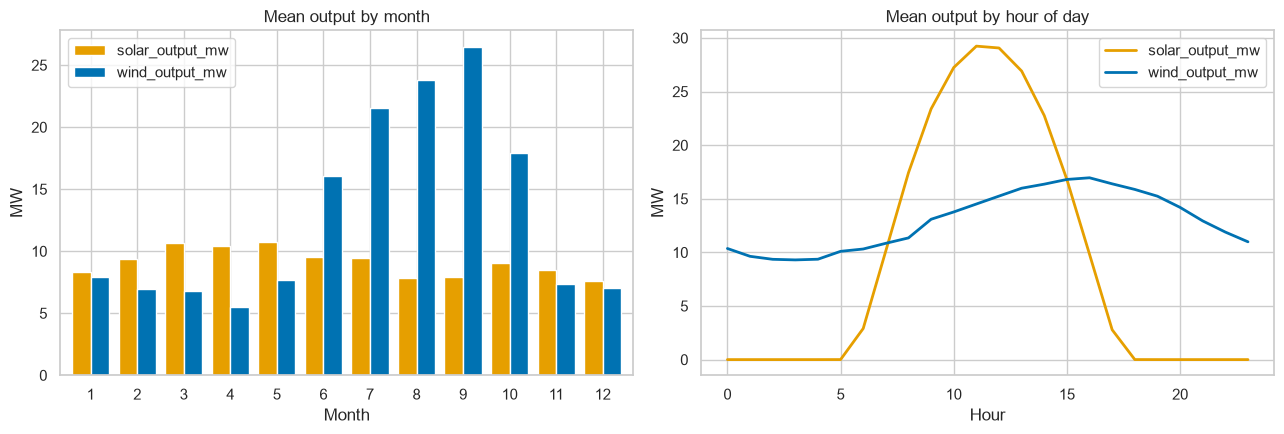

Month with highest mean solar: 5 | highest mean wind: 9


In [4]:
monthly = df.groupby(df.index.month)[["solar_output_mw", "wind_output_mw"]].mean()
hourly = df.groupby(df.index.hour)[["solar_output_mw", "wind_output_mw"]].mean()

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
monthly.plot(kind="bar", ax=axes[0], color=["#e69f00", "#0072b2"], width=0.8)
axes[0].set_title("Mean output by month"); axes[0].set_xlabel("Month"); axes[0].set_ylabel("MW")
axes[0].tick_params(axis="x", rotation=0)
hourly.plot(ax=axes[1], color=["#e69f00", "#0072b2"], lw=2)
axes[1].set_title("Mean output by hour of day"); axes[1].set_xlabel("Hour"); axes[1].set_ylabel("MW")
plt.tight_layout(); plt.show()

print("Month with highest mean solar:", monthly.solar_output_mw.idxmax(), "| highest mean wind:", monthly.wind_output_mw.idxmax())

### 2.3 Output distributions (KDE)

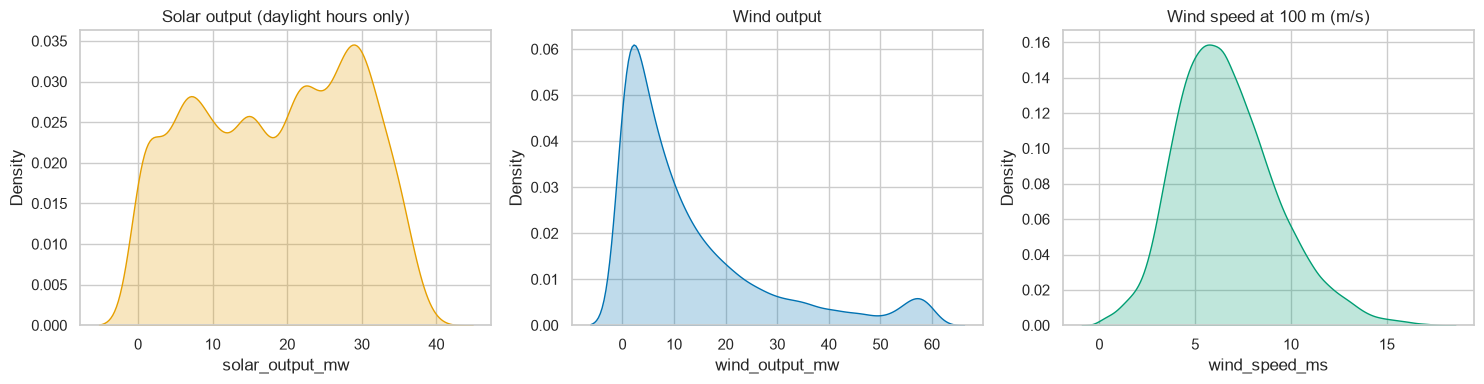

Share of hours with zero solar output: 50.5%
Share of hours with zero wind output : 7.3%
Solar capacity factor: 18.2%
Wind capacity factor : 21.6%


In [5]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
sns.kdeplot(df.loc[df.solar_output_mw > 0, "solar_output_mw"], fill=True, color="#e69f00", ax=axes[0])
axes[0].set_title("Solar output (daylight hours only)")
sns.kdeplot(df.wind_output_mw, fill=True, color="#0072b2", ax=axes[1])
axes[1].set_title("Wind output")
sns.kdeplot(df.wind_speed_ms, fill=True, color="#009e73", ax=axes[2])
axes[2].set_title("Wind speed at 100 m (m/s)")
for ax in axes: ax.set_ylabel("Density")
plt.tight_layout(); plt.show()

print("Share of hours with zero solar output: %.1f%%" % (100 * (df.solar_output_mw == 0).mean()))
print("Share of hours with zero wind output : %.1f%%" % (100 * (df.wind_output_mw == 0).mean()))
print("Solar capacity factor: %.1f%%" % (100 * df.solar_output_mw.mean() / SOLAR_CAP))
print("Wind capacity factor : %.1f%%" % (100 * df.wind_output_mw.mean() / WIND_CAP))

### 2.4 Physical relationships: irradiance -> solar, wind speed -> wind

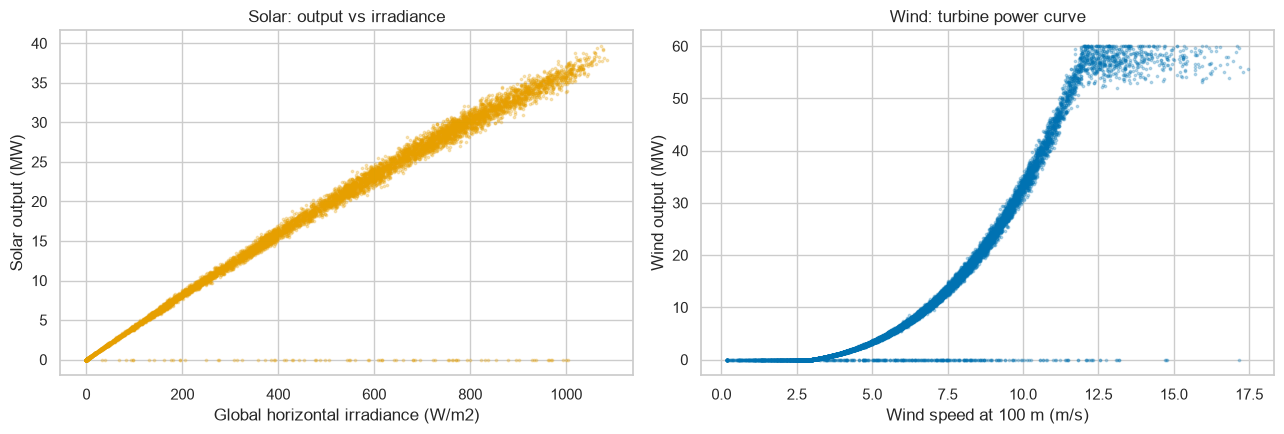

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].scatter(df.ghi_wm2, df.solar_output_mw, s=3, alpha=0.25, color="#e69f00")
axes[0].set_xlabel("Global horizontal irradiance (W/m2)"); axes[0].set_ylabel("Solar output (MW)")
axes[0].set_title("Solar: output vs irradiance")
axes[1].scatter(df.wind_speed_ms, df.wind_output_mw, s=3, alpha=0.25, color="#0072b2")
axes[1].set_xlabel("Wind speed at 100 m (m/s)"); axes[1].set_ylabel("Wind output (MW)")
axes[1].set_title("Wind: turbine power curve")
plt.tight_layout(); plt.show()

### 2.5 Correlation heatmap

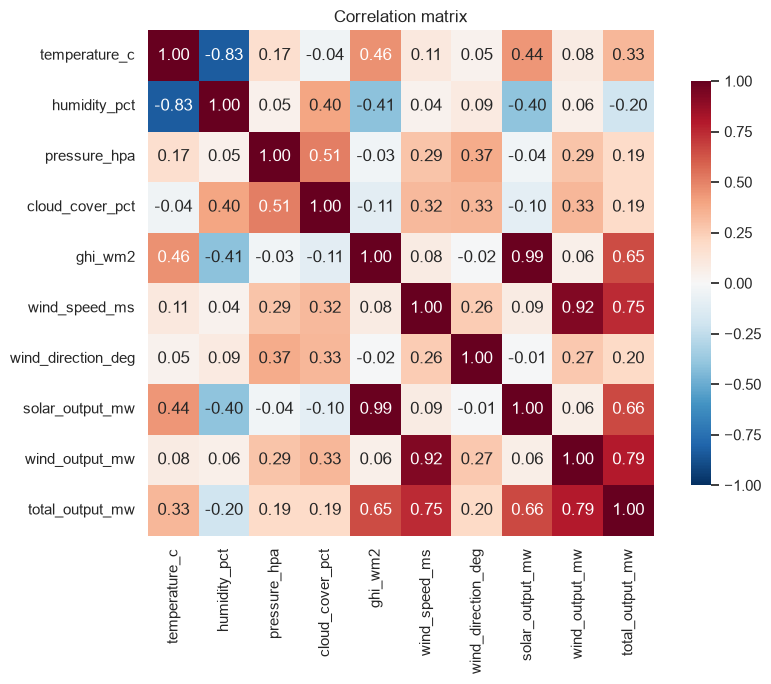

Correlation with solar_output_mw:
ghi_wm2               0.990
temperature_c         0.443
wind_speed_ms         0.086
wind_output_mw        0.064
wind_direction_deg   -0.014
pressure_hpa         -0.035
cloud_cover_pct      -0.100
humidity_pct         -0.398

Correlation with wind_output_mw:
wind_speed_ms         0.922
cloud_cover_pct       0.331
pressure_hpa          0.287
wind_direction_deg    0.272
temperature_c         0.085
solar_output_mw       0.064
humidity_pct          0.062
ghi_wm2               0.060


In [7]:
corr = df.corr(numeric_only=True)
plt.figure(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1, square=True, cbar_kws={"shrink": 0.8})
plt.title("Correlation matrix"); plt.tight_layout(); plt.show()

print("Correlation with solar_output_mw:")
print(corr["solar_output_mw"].drop(["solar_output_mw", "total_output_mw"]).sort_values(ascending=False).round(3).to_string())
print()
print("Correlation with wind_output_mw:")
print(corr["wind_output_mw"].drop(["wind_output_mw", "total_output_mw"]).sort_values(ascending=False).round(3).to_string())

## 3. Feature engineering

For each target the model uses:

- **Weather:** temperature, humidity, pressure, cloud cover, irradiance, wind speed, wind direction (treated as the day-ahead weather forecast)
- **Calendar signals:** hour and day-of-year as sine/cosine pairs, so 23:00 is close to 00:00
- **Output history (at least 24 h old):** the output exactly 24 h earlier, and the mean of the 24 h window ending 24 h earlier - these are known when a day-ahead forecast is issued

In [8]:
base = df.copy()
base["hour_sin"] = np.sin(2 * np.pi * base.index.hour / 24)
base["hour_cos"] = np.cos(2 * np.pi * base.index.hour / 24)
base["doy_sin"] = np.sin(2 * np.pi * base.index.dayofyear / 365.25)
base["doy_cos"] = np.cos(2 * np.pi * base.index.dayofyear / 365.25)

WEATHER = ["temperature_c", "humidity_pct", "pressure_hpa", "cloud_cover_pct",
           "ghi_wm2", "wind_speed_ms", "wind_direction_deg"]
CALENDAR = ["hour_sin", "hour_cos", "doy_sin", "doy_cos"]

def make_dataset(target):
    d = base[WEATHER + CALENDAR + [target]].copy()
    d["lag_24h"] = d[target].shift(24)
    d["roll_mean_24h_lag24"] = d[target].shift(24).rolling(24).mean()
    d = d.dropna()
    X, y = d.drop(columns=[target]), d[target]
    return X, y

TARGETS = {"solar_output_mw": SOLAR_CAP, "wind_output_mw": WIND_CAP}
datasets = {t: make_dataset(t) for t in TARGETS}
X_solar, _ = datasets["solar_output_mw"]
print("Feature columns:", list(X_solar.columns))
print("Rows after dropping lag warm-up:", len(X_solar))

Feature columns: ['temperature_c', 'humidity_pct', 'pressure_hpa', 'cloud_cover_pct', 'ghi_wm2', 'wind_speed_ms', 'wind_direction_deg', 'hour_sin', 'hour_cos', 'doy_sin', 'doy_cos', 'lag_24h', 'roll_mean_24h_lag24']
Rows after dropping lag warm-up: 17497


## 4. Chronological train / test split

Time series must not be shuffled: shuffling would let the model see the future. The models are trained on **2023-01-01 to 2024-06-30** (18 months) and tested on **2024-07-01 to 2024-12-31** (6 months, unseen).

In [9]:
SPLIT = pd.Timestamp("2024-07-01")
splits = {}
for t, (X, y) in datasets.items():
    tr, te = X.index < SPLIT, X.index >= SPLIT
    splits[t] = dict(X_train=X[tr], y_train=y[tr], X_test=X[te], y_test=y[te])

s = splits["solar_output_mw"]
print("Train rows:", len(s["X_train"]), "|", s["X_train"].index.min().date(), "->", s["X_train"].index.max().date())
print("Test rows :", len(s["X_test"]),  "|", s["X_test"].index.min().date(),  "->", s["X_test"].index.max().date())

Train rows: 13081 | 2023-01-02 -> 2024-06-30
Test rows : 4416 | 2024-07-01 -> 2024-12-31


## 5. Models

| Model | Role |
|---|---|
| Persistence (output 24 h ago) | Baseline every model must beat |
| Linear Regression | Linear benchmark |
| Decision Tree | Simple non-linear model |
| Random Forest | Bagged trees |
| Gradient Boosting | Sequential boosted trees |

In [10]:
def build_models():
    return {
        "Linear Regression": make_pipeline(StandardScaler(), LinearRegression()),
        "Decision Tree": DecisionTreeRegressor(max_depth=12, min_samples_leaf=5, random_state=RANDOM_STATE),
        "Random Forest": RandomForestRegressor(n_estimators=200, min_samples_leaf=2, n_jobs=-1, random_state=RANDOM_STATE),
        "Gradient Boosting": GradientBoostingRegressor(n_estimators=300, learning_rate=0.05, max_depth=4,
                                                       subsample=0.8, random_state=RANDOM_STATE),
    }

def evaluate(y_true, y_pred, cap):
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    return {"MAE (MW)": mean_absolute_error(y_true, y_pred), "RMSE (MW)": rmse,
            "R2": r2_score(y_true, y_pred), "nRMSE (% of capacity)": 100 * rmse / cap}

rows, predictions, fitted = [], {}, {}
for target, cap in TARGETS.items():
    sp = splits[target]
    # persistence baseline
    base_pred = sp["X_test"]["lag_24h"].values
    rows.append({"Target": target, "Model": "Persistence (24 h)", **evaluate(sp["y_test"], base_pred, cap)})
    predictions[(target, "Persistence (24 h)")] = pd.Series(base_pred, index=sp["y_test"].index)
    for name, model in build_models().items():
        model.fit(sp["X_train"], sp["y_train"])
        pred = np.clip(model.predict(sp["X_test"]), 0, cap)
        predictions[(target, name)] = pd.Series(pred, index=sp["y_test"].index)
        fitted[(target, name)] = model
        rows.append({"Target": target, "Model": name, **evaluate(sp["y_test"], pred, cap)})

results = pd.DataFrame(rows)
print(results.round(3).to_string(index=False))

         Target              Model  MAE (MW)  RMSE (MW)     R2  nRMSE (% of capacity)
solar_output_mw Persistence (24 h)     1.468      3.530  0.898                  7.060
solar_output_mw  Linear Regression     0.473      1.348  0.985                  2.696
solar_output_mw      Decision Tree     0.316      1.434  0.983                  2.868
solar_output_mw      Random Forest     0.272      1.352  0.985                  2.704
solar_output_mw  Gradient Boosting     0.277      1.341  0.985                  2.682
 wind_output_mw Persistence (24 h)    13.098     18.022 -0.214                 30.036
 wind_output_mw  Linear Regression     3.898      5.766  0.876                  9.610
 wind_output_mw      Decision Tree     1.162      3.954  0.942                  6.590
 wind_output_mw      Random Forest     1.009      3.523  0.954                  5.872
 wind_output_mw  Gradient Boosting     1.043      3.667  0.950                  6.112


## 6. Model comparison leaderboard

--- solar_output_mw (sorted by RMSE, lower is better) ---
             Model  MAE (MW)  RMSE (MW)    R2  nRMSE (% of capacity)
 Gradient Boosting     0.277      1.341 0.985                  2.682
 Linear Regression     0.473      1.348 0.985                  2.696
     Random Forest     0.272      1.352 0.985                  2.704
     Decision Tree     0.316      1.434 0.983                  2.868
Persistence (24 h)     1.468      3.530 0.898                  7.060

--- wind_output_mw (sorted by RMSE, lower is better) ---
             Model  MAE (MW)  RMSE (MW)     R2  nRMSE (% of capacity)
     Random Forest     1.009      3.523  0.954                  5.872
 Gradient Boosting     1.043      3.667  0.950                  6.112
     Decision Tree     1.162      3.954  0.942                  6.590
 Linear Regression     3.898      5.766  0.876                  9.610
Persistence (24 h)    13.098     18.022 -0.214                 30.036



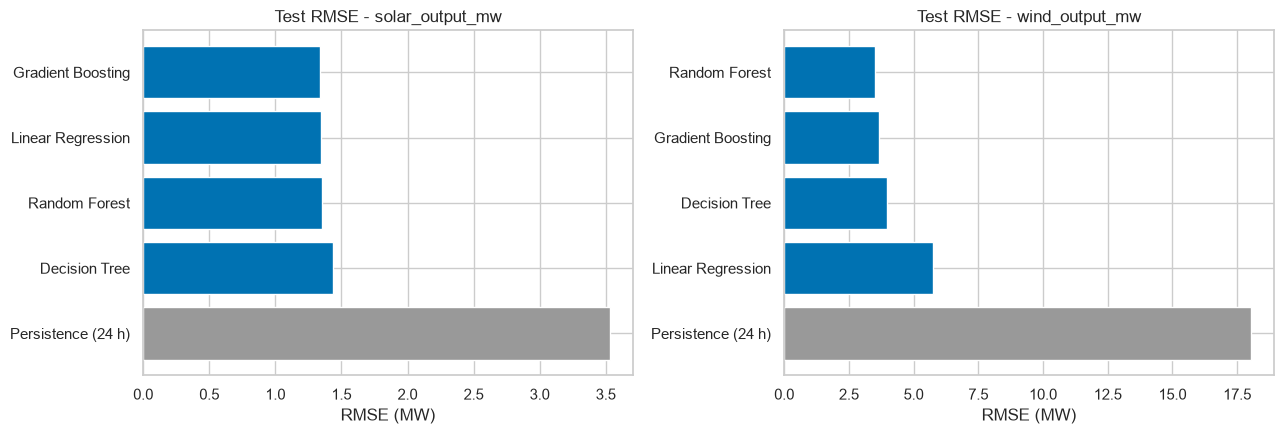

In [11]:
leaderboard = {}
for target in TARGETS:
    leaderboard[target] = (results[results.Target == target]
                           .sort_values("RMSE (MW)").reset_index(drop=True)
                           .drop(columns="Target"))
    print(f"--- {target} (sorted by RMSE, lower is better) ---")
    print(leaderboard[target].round(3).to_string(index=False))
    print()

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, target in zip(axes, TARGETS):
    lb = leaderboard[target].sort_values("RMSE (MW)", ascending=False)
    ax.barh(lb.Model, lb["RMSE (MW)"], color=["#999999" if "Persistence" in m else "#0072b2" for m in lb.Model])
    ax.set_title(f"Test RMSE - {target}"); ax.set_xlabel("RMSE (MW)")
plt.tight_layout(); plt.show()

## 7. Predicted vs actual on unseen test data

Best model per target: {'solar_output_mw': 'Gradient Boosting', 'wind_output_mw': 'Random Forest'}


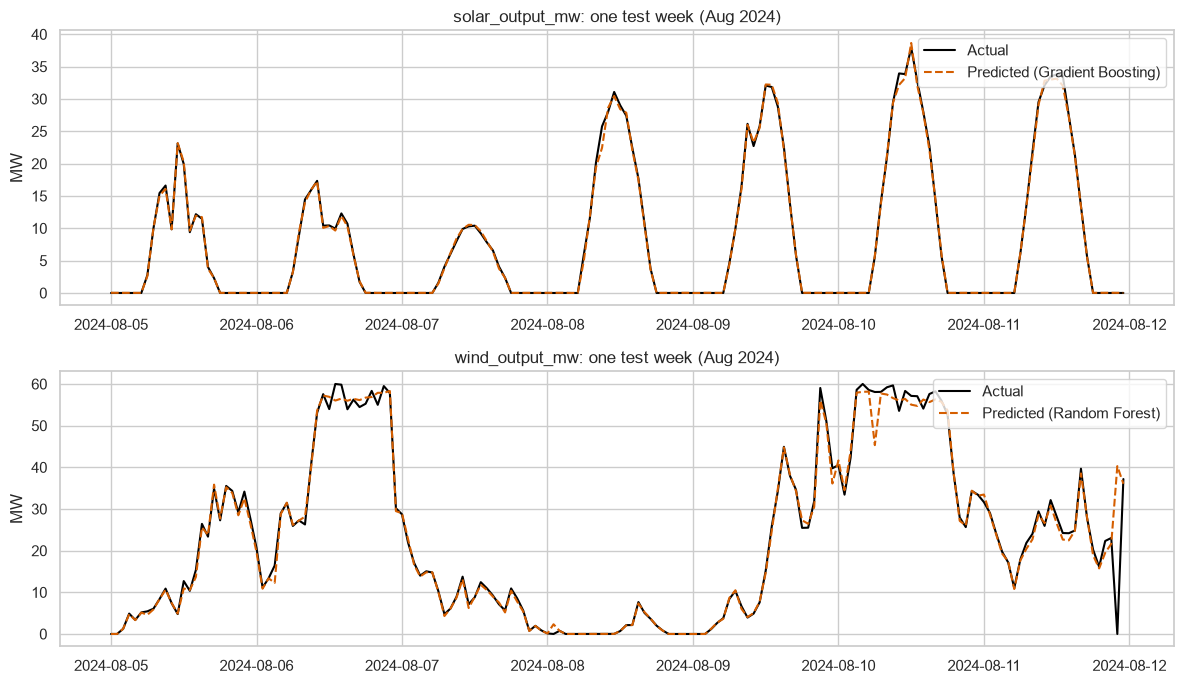

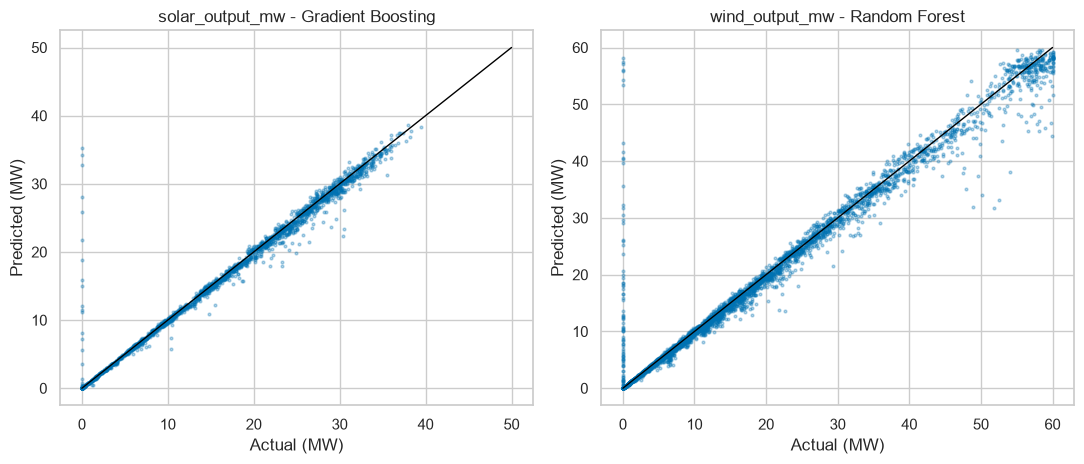

In [12]:
best = {t: leaderboard[t].iloc[0]["Model"] for t in TARGETS}
print("Best model per target:", best)

fig, axes = plt.subplots(2, 1, figsize=(12, 7))
for ax, target in zip(axes, TARGETS):
    sp = splits[target]
    wk = slice("2024-08-05", "2024-08-11 23:00")
    ax.plot(sp["y_test"].loc[wk].index, sp["y_test"].loc[wk], label="Actual", color="black", lw=1.5)
    ax.plot(sp["y_test"].loc[wk].index, predictions[(target, best[target])].loc[wk],
            label=f"Predicted ({best[target]})", color="#d55e00", lw=1.5, ls="--")
    ax.set_title(f"{target}: one test week (Aug 2024)"); ax.set_ylabel("MW"); ax.legend(loc="upper right")
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(1, 2, figsize=(11, 4.8))
for ax, (target, cap) in zip(axes, TARGETS.items()):
    ax.scatter(splits[target]["y_test"], predictions[(target, best[target])], s=4, alpha=0.3, color="#0072b2")
    ax.plot([0, cap], [0, cap], color="black", lw=1)
    ax.set_xlabel("Actual (MW)"); ax.set_ylabel("Predicted (MW)"); ax.set_title(f"{target} - {best[target]}")
plt.tight_layout(); plt.show()

### 7.1 Combined solar + wind forecast

In [13]:
comb_rows = []
idx_common = splits["solar_output_mw"]["y_test"].index.intersection(splits["wind_output_mw"]["y_test"].index)
actual_total = (splits["solar_output_mw"]["y_test"].loc[idx_common] + splits["wind_output_mw"]["y_test"].loc[idx_common])
total_cap = SOLAR_CAP + WIND_CAP
for name in ["Persistence (24 h)", "Linear Regression", "Decision Tree", "Random Forest", "Gradient Boosting"]:
    pred_total = (predictions[("solar_output_mw", name)].loc[idx_common] + predictions[("wind_output_mw", name)].loc[idx_common])
    comb_rows.append({"Model": name, **evaluate(actual_total, pred_total, total_cap)})
combined = pd.DataFrame(comb_rows).sort_values("RMSE (MW)").reset_index(drop=True)
print("Combined (solar + wind) forecast, total capacity 110 MW")
print(combined.round(3).to_string(index=False))

Combined (solar + wind) forecast, total capacity 110 MW
             Model  MAE (MW)  RMSE (MW)    R2  nRMSE (% of capacity)
     Random Forest     1.192      3.797 0.966                  3.452
 Gradient Boosting     1.224      3.914 0.964                  3.558
     Decision Tree     1.368      4.228 0.958                  3.844
 Linear Regression     3.960      5.913 0.917                  5.375
Persistence (24 h)    13.456     18.568 0.183                 16.880


## 8. Time-series cross-validation (robustness check)

In [14]:
tscv = TimeSeriesSplit(n_splits=4)
cv_rows = []
for target, cap in TARGETS.items():
    X, y = datasets[target]
    for name in ["Linear Regression", "Decision Tree", "Random Forest", "Gradient Boosting"]:
        fold_rmse = []
        for tr_idx, te_idx in tscv.split(X):
            m = build_models()[name]
            m.fit(X.iloc[tr_idx], y.iloc[tr_idx])
            p = np.clip(m.predict(X.iloc[te_idx]), 0, cap)
            fold_rmse.append(np.sqrt(mean_squared_error(y.iloc[te_idx], p)))
        cv_rows.append({"Target": target, "Model": name,
                        "CV RMSE mean (MW)": np.mean(fold_rmse), "CV RMSE std (MW)": np.std(fold_rmse)})
cv_results = pd.DataFrame(cv_rows)
print(cv_results.round(3).to_string(index=False))

         Target             Model  CV RMSE mean (MW)  CV RMSE std (MW)
solar_output_mw Linear Regression              1.560             0.180
solar_output_mw     Decision Tree              1.775             0.215
solar_output_mw     Random Forest              1.647             0.167
solar_output_mw Gradient Boosting              1.757             0.242
 wind_output_mw Linear Regression              6.169             2.813
 wind_output_mw     Decision Tree              3.432             1.048
 wind_output_mw     Random Forest              3.153             1.059
 wind_output_mw Gradient Boosting              3.222             1.132


## 9. Feature importance

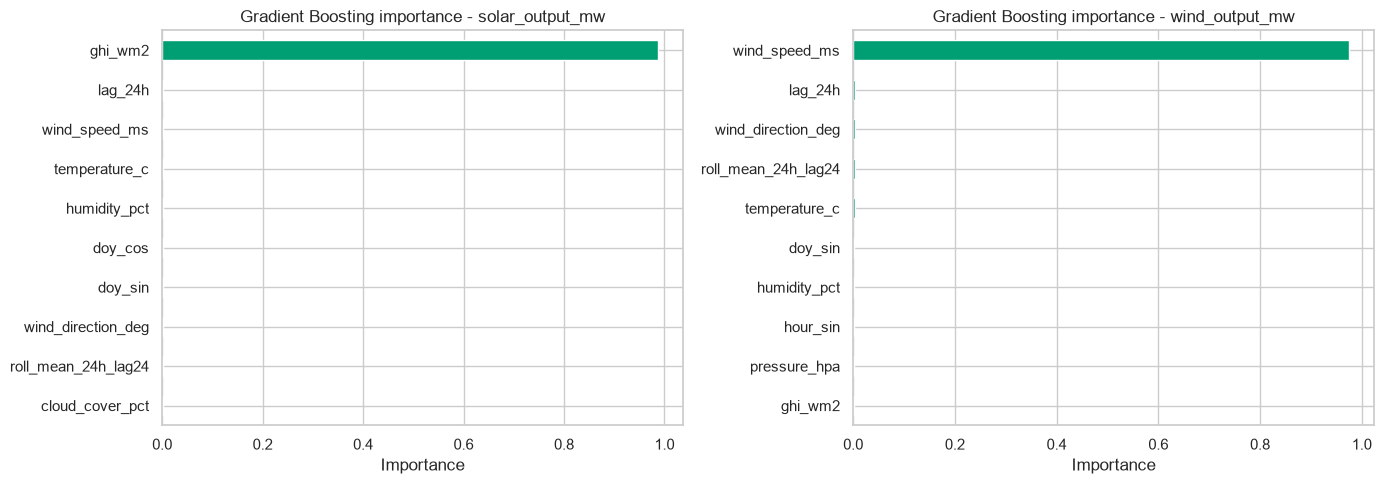

Top 5 features for solar_output_mw:
ghi_wm2          0.987
lag_24h          0.002
wind_speed_ms    0.002
temperature_c    0.002
humidity_pct     0.001

Top 5 features for wind_output_mw:
wind_speed_ms          0.975
lag_24h                0.003
wind_direction_deg     0.003
roll_mean_24h_lag24    0.003
temperature_c          0.003



In [15]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
importances = {}
for ax, target in zip(axes, TARGETS):
    model = fitted[(target, "Gradient Boosting")]
    imp = pd.Series(model.feature_importances_, index=splits[target]["X_train"].columns).sort_values()
    importances[target] = imp.sort_values(ascending=False)
    imp.tail(10).plot(kind="barh", ax=ax, color="#009e73")
    ax.set_title(f"Gradient Boosting importance - {target}"); ax.set_xlabel("Importance")
plt.tight_layout(); plt.show()

for target in TARGETS:
    print(f"Top 5 features for {target}:")
    print(importances[target].head(5).round(3).to_string())
    print()

## 10. Conclusions

- **Every model beats the 24-hour persistence baseline** on both targets. Persistence is especially poor for wind (test R2 = -0.21) because wind speed barely repeats from one day to the next.
- **Wind: non-linear models matter.** Random Forest reaches a test RMSE of 3.52 MW (5.9% of capacity) versus 5.77 MW (9.6%) for Linear Regression, because the turbine power curve (cubic ramp, rated-power plateau, cut-out) is strongly non-linear.
- **Solar: the models are essentially tied.** Test RMSE ranges from 1.34 to 1.43 MW across all four models, and Linear Regression has the lowest cross-validated RMSE (1.56 MW). Output is almost linear in irradiance (correlation 0.99), so a simple model is enough for RMSE; the tree models mainly reduce MAE (0.27-0.32 MW vs 0.47 MW) around sunrise/sunset and near-zero hours.
- **Feature importance** is dominated by irradiance for solar (0.99) and wind speed for wind (0.98); the 24-hour lag features add little once weather inputs are known.
- **Combined 110 MW portfolio:** Random Forest gives the best total forecast (RMSE 3.80 MW, R2 0.966).

**Limitations**
- The data is synthetic and generated from the same physical relationships the models learn, so these scores are optimistic and do not predict performance on a real plant.
- Weather inputs are the observed values, not real numerical-weather-prediction forecasts, so real forecast error would be higher.
- Random outages (1-2% of hours) are unpredictable and set a floor on achievable error.

**Next steps:** use real NWP forecasts and plant SCADA data, add probabilistic (quantile) forecasts, and test LightGBM/LSTM models.